# 01 - Exploratory Data Analysis

This notebook profiles the **Elliptic-style Bitcoin transaction data** to settle three questions before any modelling: 
1. How to **validate** models when the data drifts over time?
2. Which **model family** suits the features?
3. Does the **payment graph** carry signals that a model can still use at test time?

## Background
Bitcoin is a public ledger in which every **transaction** spends outputs of earlier transactions. Most transactions are legitimate (**licit**), but some are linked to crime such as scams, ransomware or darknet markets (**illicit**). The task is to predict, for each transaction in the test set, the **probability that it is illicit**, scored by ROC-AUC.

## Data
| File | What it contains |
|---|---|
| `train.csv` | Transactions from time steps 1-35, with labels: `1` = illicit, `0` = licit, `NaN` = unknown |
| `test.csv` | Transactions from time steps 36-49, with no labels |
| `txs_edgelist.csv` | Payment flows between transactions: each row `txId1 -> txId2` means coins created by `txId1` are spent by `txId2` |
| `sample_submission.csv` | The submission format: one row per test transaction, columns `index,target` |

Each transaction has an id (`txId`), a time step (`time_step`) and 165 anonymised, pre-normalised features (`feat_1` to `feat_165`).

## Questions this notebook answers
1. **Section 1**: How much labeled data is there, and how rare are illicit transactions?
2. **Section 2**: Is the data clean: missing values, duplicates, overlap between train and test?
3. **Section 3**: How does the share of illicit transactions change over time, and what does that mean for validation?
4. **Section 4**: Which features separate the classes (illicit / licit), how are they structured, and do they shift between train and test?
5. **Section 5**: Does the transaction graph carry useful signal, and which neighbours can a model actually see at test time?

**Section 6** collects the findings and what each one implies for modelling.


## 0. Setup
Imports and project helpers. File paths and column names live in `src/data.py`, so every notebook reads the data in the same way.

**Helpers from `src/data.py`**
- `load_train`, `load_test`, `load_edges`, `load_sample_submission`: read the four kaggle files from `data/raw/`.
- `labeled(df)`: keeps the rows with a known label (0 or 1).
- `ID_COL`, `TIME_COL`, `LABEL_COL`, `TEST_INDEX_COL`, `FEATURE_COLS`: the shared column names.

In [1]:
import sys
sys.path.append("..")  # add the repo root so `src` can be imported from inside notebooks/

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

from src.data import (load_train, load_test, load_edges, load_sample_submission, labeled, 
                      ID_COL, TIME_COL, LABEL_COL, TEST_INDEX_COL, FEATURE_COLS)

pd.set_option("display.max_columns", 50)  # show wide tables without cutting columns

## 1. Load data
Load the four files, check their sizes, and confirm that the sample submission lists the test rows in the order of `test.csv`, since every submission must follow that order.

In [2]:
train = load_train()  # time steps 1-35, label is NaN when unknown
test = load_test()    # time steps 36-49, extra `index` column used as row id for submission
edges = load_edges()  # directed edges between nodes: an output of txId1 is spent by txId2
sample = load_sample_submission()  # the format Kaggle expects

print(f"train: {train.shape[0]:,} rows x {train.shape[1]} columns")
print(f"test : {test.shape[0]:,} rows x {test.shape[1]} columns")
print(f"edges: {edges.shape[0]:,} rows")

# The submission must list the test rows in the same order as test.csv
print("Sample submission matches test.csv row order:", sample[TEST_INDEX_COL].equals(test[TEST_INDEX_COL]))

train: 141,772 rows x 168 columns
test : 15,329 rows x 168 columns
edges: 234,355 rows
Sample submission matches test.csv row order: True


### Label distribution
Only labeled transactions can be used to train and evaluate a supervised model, so the first question is how many there are.

In [3]:
# Give the label codes readable names
# NaN means the data provider did not label it
label_names = train[LABEL_COL].map({0: "licit", 1: "illicit"}).fillna("unknown")

label_counts = label_names.value_counts().to_frame("count")
label_counts["share_of_train"] = (label_counts["count"] / len(train)).round(3)
label_counts

,count,share_of_train
label,,
unknown,110537,0.780
licit,27591,0.195
illicit,3644,0.026


Keep only labeled rows in training data. Every later section that needs labels uses `lab`.

In [4]:
lab = labeled(train)  # keep only rows with a known label (0 or 1)
print(f"Labeled rows: {len(lab):,}")
print(f"Illicit share among labeled rows: {lab[LABEL_COL].mean():.1%}")

Labeled rows: 31,235
Illicit share among labeled rows: 11.7%


**Takeaway:** 78% of the training transactions are unlabeled, and only 11.7% of the labeled ones are illicit: a clear **class imbalance**. 

Accuracy would be misleading here, because predicting "licit" for everything is already 88.3% accurate. The competition is scored with **ROC-AUC**, which measures how well the predicted probabilities rank illicit transactions above licit ones; constantly predicting "licit" for everything only scores 0.5.

Unlabeled rows cannot be used to train or score a model, but they remain part of the transaction graph (section 5).

## 2. Data Quality Checks

Check for missing values, duplicated transactions and transactions that appear in both train and test files, and whether the features are really pre-normalised as the data description says.

In [5]:
print("Missing feature values (train):", int(train[FEATURE_COLS].isna().sum().sum()))
print("Missing feature values (test): ", int(test[FEATURE_COLS].isna().sum().sum()))
print("Duplicated txIds (train):", int(train[ID_COL].duplicated().sum()))
print("Duplicated txIds (test):", int(test[ID_COL].duplicated().sum()))
print("txIds in both train and test:", len(set(train[ID_COL]) & set(test[ID_COL])))
print(f"Time steps: train {train[TIME_COL].min()}-{train[TIME_COL].max()}, test {test[TIME_COL].min()}-{test[TIME_COL].max()}")

# The features are said to be pre-normalised (mean 0, standard deviation 1). Check this per feature.
summary = train[FEATURE_COLS].agg(["mean", "std", "max"]).T  # one row per feature
print(f"\nMedian of the 165 feature means: {summary['mean'].median():.3f}")
print(f"Median of the 165 feature standard deviations: {summary['std'].median():.2f}")
print(f"Features whose maximum is above 3 standard deviations: {(summary['max'] > 3).sum()} of {len(FEATURE_COLS)}")

Missing feature values (train): 0
Missing feature values (test):  0
Duplicated txIds (train): 0
Duplicated txIds (test): 0
txIds in both train and test: 0
Time steps: train 1-35, test 36-49

Median of the 165 feature means: -0.002
Median of the 165 feature standard deviations: 1.02
Features whose maximum is above 3 standard deviations: 117 of 165


**Takeaway:** No missing values, no duplicates and no overlap between train and test. Hence no cleaning is needed. The test set lies strictly after the training period (steps 36-49 vs 1-35).

Features are centred (mean ≈ 0, standard deviation ≈ 1) but heavy-tailed: 117 of 165 features reach values above 3 standard deviations.
Scale-sensitive models such as logistic regression are exposed to these tails, while tree-based models, which depend only on the order of the values, are not.

## 3. How the data changes over time

The test set comes from **later** time steps than the training set. If the share of illicit transactions, or the way they behave, changes over time (**concept drift**), a model that scores well on randomly chosen rows in the training set may perform worse in future test periods.

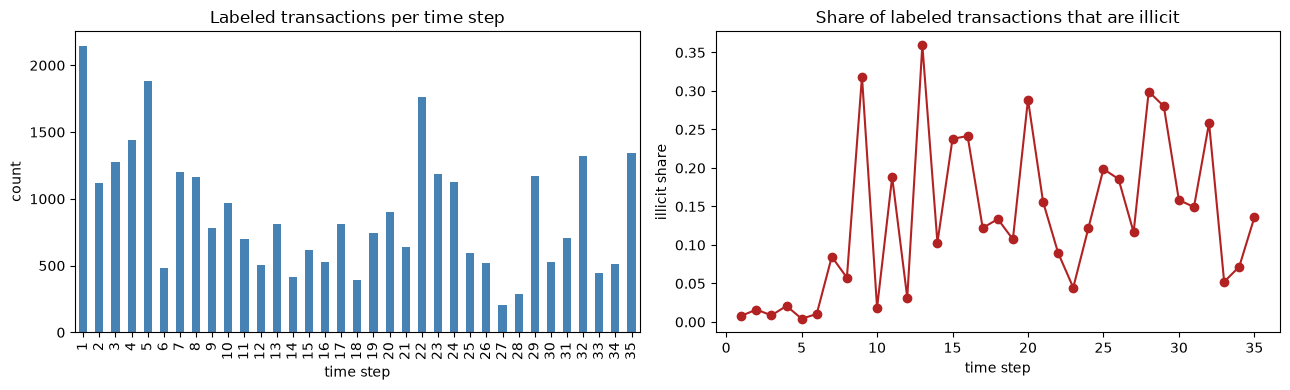

Illicit share ranges from 0.4% to 36.0%


In [6]:
# Per time step: Number of labeled transactions and the share of illicit transactions among them
labeled_per_time_step = lab.groupby(TIME_COL)[LABEL_COL].agg(n_labeled="size", illicit_share="mean")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
labeled_per_time_step["n_labeled"].plot.bar(ax=ax[0], color="steelblue")
ax[0].set(title="Labeled transactions per time step", xlabel="time step", ylabel="count")
labeled_per_time_step["illicit_share"].plot(ax=ax[1], marker="o", color="firebrick")
ax[1].set(title="Share of labeled transactions that are illicit", xlabel="time step", ylabel="illicit share")
plt.tight_layout()
plt.show()

print(f"Illicit share ranges from {labeled_per_time_step['illicit_share'].min():.1%} to {labeled_per_time_step['illicit_share'].max():.1%}")

How many test transactions fall in each future time step? Steps with more rows carry more weight in the pooled test AUC.

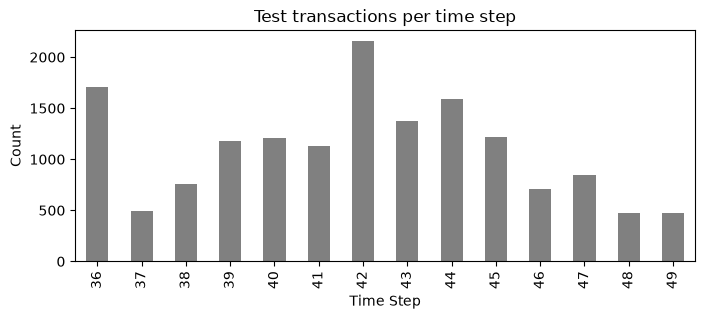

14 test time steps, with 471 to 2,154 transactions each


In [7]:
# How many test transactions fall in each future time step
test_per_time_step = test.groupby(TIME_COL).size()

test_per_time_step.plot.bar(figsize=(8, 3), color="gray", title="Test transactions per time step")
plt.xlabel("Time Step")
plt.ylabel("Count")
plt.show()

print(f"{len(test_per_time_step)} test time steps, with {test_per_time_step.min():,} to {test_per_time_step.max():,} transactions each")

**Takeaway:** The share of illicit transactions among labeled training rows varies from 0.4% to 36% between time steps, so the data is **not stable over time**. 

Model performance must therefore be estimated with a **time-based split**: train on earlier time steps, validate on later ones (`02_validation_setup.ipynb`).

The test AUC ranks the transactions of all 14 test steps together. A model that learns "this kind of time step had many illicit transactions" could carry that step-level share into test steps where it no longer holds. The final notebook addresses this risk with a per-step offset (`05_model_comparison.ipynb`).

## 4. Which features separate illicit from licit?
Each feature is used **on its own** as a score and its ROC-AUC is computed on the labeled data.

An AUC far from 0.5, above or below, means the feature alone already separates the classes well.
I report `max(AUC, 1-AUC)` so a feature that ranks illicit transactions low counts as strongly as one that ranks them high.

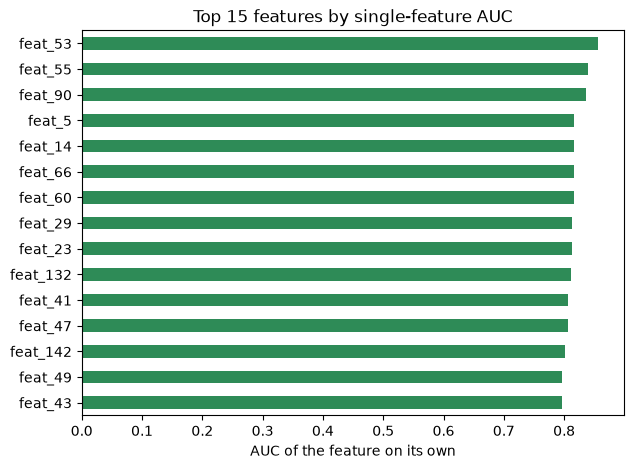

Features with single-feature AUC > 0.8: 13 of 165 features


In [8]:
single_feature_auc = pd.Series(
    {f: roc_auc_score(lab[LABEL_COL], lab[f]) for f in FEATURE_COLS}
)
separation = np.maximum(single_feature_auc, 1 - single_feature_auc)  # direction-free separation score
top = separation.sort_values(ascending=False)

top.head(15).sort_values().plot.barh(figsize=(7, 5), color="seagreen", 
                                     title="Top 15 features by single-feature AUC")
plt.xlabel("AUC of the feature on its own")
plt.show()

print(f"Features with single-feature AUC > 0.8: {(separation > 0.8).sum()} of {len(FEATURE_COLS)} features")

The two strongest features in more detail: how differently are they distributed in each class?

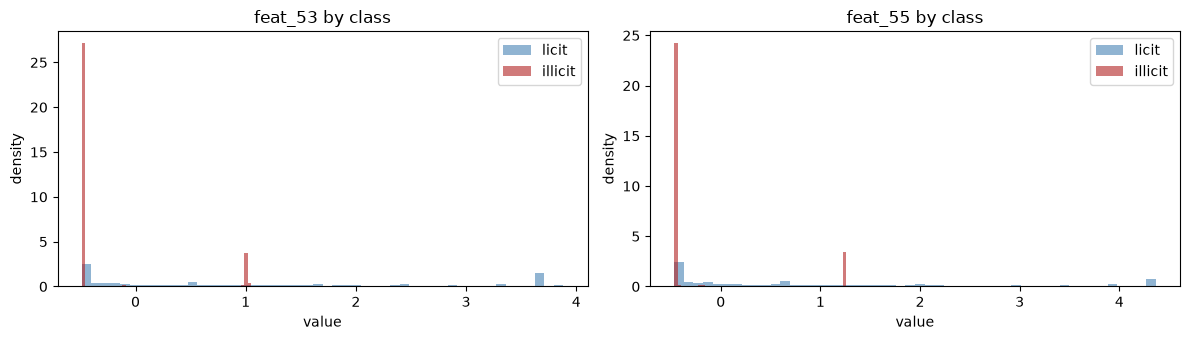

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for a, f in zip(ax, top.index[:2]):
    for value, name, color in [(0, "licit", "steelblue"), (1, "illicit", "firebrick")]:
        values = lab.loc[lab[LABEL_COL] == value, f]
        # clip extreme values so the bulk of the distribution is visible
        a.hist(values.clip(values.quantile(0.01), values.quantile(0.99)), bins=50,
               alpha=0.6, density=True, label=name, color=color)
    a.set(title=f"{f} by class", xlabel="value", ylabel="density")
    a.legend()
plt.tight_layout()
plt.show()

**Takeaway:** 13 features reach an AUC above 0.8 on their own, so even simple models should score high.

On the two strongest features, illicit transactions concentrate on a few specific values, while licit ones are spread out.

The challenge in this competition is therefore less about finding signal and more about keeping that signal **reliable in future time steps**.

### Feature groups
In the original Elliptic dataset, the first features describe the transaction itself (**local**) and the rest summarise its neighbours (**aggregated**). 

A correlation heatmap shows such groups as blocks of strongly related features.

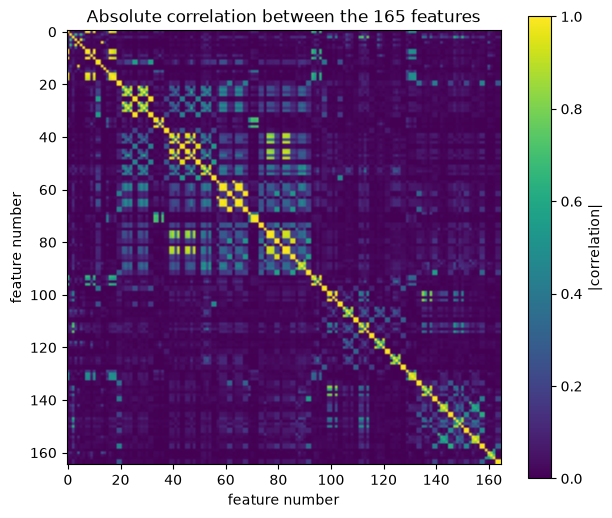

In [10]:
corr = train[FEATURE_COLS].corr().abs()  # absolute correlation: strength of the relationship, ignoring sign

plt.figure(figsize=(7, 6))
plt.imshow(corr, cmap="viridis", vmin=0, vmax=1)
plt.colorbar(label="|correlation|")
plt.title("Absolute correlation between the 165 features")
plt.xlabel("feature number")
plt.ylabel("feature number")
plt.show()

**Takeaway:**

The features form clear blocks of highly correlated variables (e.g. around features 20-95 and 100-165), consistent with groups of related measurements. The block pattern changes at about feature 95, close to where the original Elliptic data switches from local to aggregated features (after feature 93). The graph features in later notebooks therefore treat the first 93 features as the transaction's own (local) features.

Many features carry overlapping information, so tree-based models, which cope well with correlated inputs, are a natural choice.

### Do the features shift between train and test?
For each feature, I compare its mean in the labeled training data (the rows models are trained on) with its mean in the test set,
measured in training standard deviations. 

Large values mean the test period looks different on that feature.

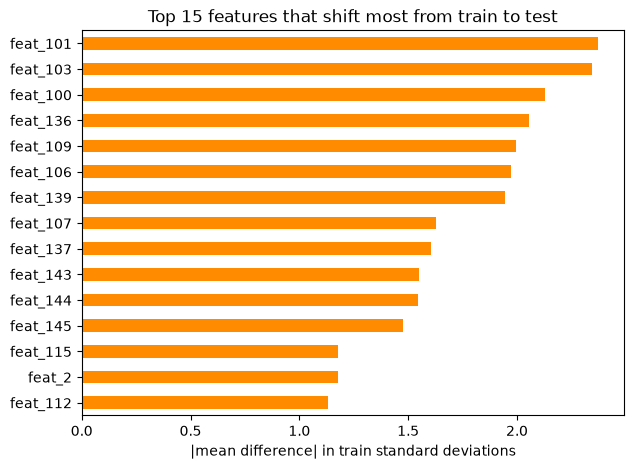

Features shifting by more than 0.5 std: 21 of 165


In [11]:
# Standardised mean difference: (test mean - train mean) / train standard deviation
shift = ((test[FEATURE_COLS].mean() - lab[FEATURE_COLS].mean()) / lab[FEATURE_COLS].std()).abs()

shift.sort_values(ascending=False).head(15).sort_values().plot.barh(
    figsize=(7, 5), color="darkorange", title="Top 15 features that shift most from train to test")
plt.xlabel("|mean difference| in train standard deviations")
plt.show()

print(f"Features shifting by more than 0.5 std: {(shift > 0.5).sum()} of {len(FEATURE_COLS)}")

**Takeaway:** 21 of the 165 features shift by more than half a standard deviation in the test period.

A model that leans heavily on these features may lose accuracy on the test set, so model choices are checked on the latest training steps (the late folds of `02_validation_setup.ipynb`), and notebook 03 checks how many features the model draws on.

## 5. The transaction graph
Money moves along chains of transactions, so illicit funds often pass through chains of connected transactions.
If the neighbours of illicit transactions are more often illicit themselves, **graph features** built from the edge list can help the model.

**Checks in this section:**
1. How the edges connect train, test and time steps.
2. Which neighbours a model can actually see (this leads to the "present" rule).
3. Degree as a feature on its own.
4. Homophily: do illicit transactions connect to other illicit transactions?

In [ ]:
train_ids, test_ids = set(train[ID_COL]), set(test[ID_COL])

# For each edge, check whether its source (txId1) and destination (txId2) are train or test transactions
src_train, dst_train = edges["txId1"].isin(train_ids), edges["txId2"].isin(train_ids)
src_test, dst_test = edges["txId1"].isin(test_ids), edges["txId2"].isin(test_ids)

print(f"Edges within train: {(src_train & dst_train).sum():,}")
print(f"Edges within test:  {(src_test & dst_test).sum():,}")
print(f"Edges between train and test: {((src_train & dst_test) | (src_test & dst_train)).sum():,}")

# Do edges ever join two different time steps? (checked on edges wheose two ends both have a row)
step_of = pd.concat([train, test]).set_index(ID_COL)[TIME_COL]  # txId -> time step
src_step, dst_step = edges["txId1"].map(step_of), edges["txId2"].map(step_of)
both_known = src_step.notna() & dst_step.notna()
print(f"Edges joining two different time steps: {(src_step[both_known] != dst_step[both_known]).sum():,}")

# Some transactions appear in the edge list but in neither file. Where are they?
endpoints = pd.concat([edges["txId1"], edges["txId2"]])
missing = set(endpoints[~endpoints.isin(train_ids | test_ids)])
touches_missing = edges["txId1"].isin(missing) | edges["txId2"].isin(missing)
print(f"\nTransactions in the edge list but in neither file: {len(missing):,}")
print(f"  edges linking one of them to a train transaction: {(touches_missing & (src_train | dst_train)).sum():,}")
print(f"  edges linking one of them to a test transaction:  {(touches_missing & (src_test | dst_test)).sum():,}")

Edges within train: 163,194
Edges within test:  12,724
Edges between train and test: 0
Edges joining two different time steps: 0

Transactions in the edge list but in neither file: 46,668
  edges linking one of them to a train transaction: 0
  edges linking one of them to a test transaction:  24,245


**Takeaway:** Every edge stays inside one time step, and no edge joins train and test. The transactions that have no row in either file are linked only to test transactions (or to each other), so they all belong to the test period.

`train.csv` keeps its unlabeled transactions (label `NaN`), but `test.csv` seems to leave out part of the test period's transactions. The next check asks what this means for the neighbours a model can see.

### Which neighbours can a model actually see?
A graph feature such as "average of my neighbours' features" can only use neighbours that have a row in our data.
I compare how often a neighbour has a row for test transactions and for labeled training transactions.

In [18]:
# Every edge seen from both ends: one row per (transaction, neighbour) pair
links = pd.concat([edges.rename(columns={"txId1": "neighbour", "txId2": "node"}),
                   edges.rename(columns={"txId2": "neighbour", "txId1": "node"})])
lab_ids = set(lab[ID_COL])
test_links = links[links["node"].isin(test_ids)]  # neighbours of test transactions
lab_links = links[links["node"].isin(lab_ids)]    # neighbours of labeled training transactions

print(f"Neighbours of test transactions that are in test.csv:            {test_links['neighbour'].isin(test_ids).mean():.1%}")
print(f"Neighbours of labeled train transactions that are in train.csv:  {lab_links['neighbour'].isin(train_ids).mean():.1%}")
print(f"Neighbours of labeled train transactions that are labeled:       {lab_links['neighbour'].isin(lab_ids).mean():.1%}")

# Share of transactions with at least one such neighbour
test_has_nb = test[ID_COL].isin(test_links.loc[test_links["neighbour"].isin(test_ids), "node"])
lab_has_nb = lab[ID_COL].isin(lab_links.loc[lab_links["neighbour"].isin(lab_ids), "node"])
print(f"\nTest transactions with at least one neighbour in test.csv:       {test_has_nb.mean():.1%}")
print(f"Labeled train transactions with at least one labeled neighbour:  {lab_has_nb.mean():.1%}")

Neighbours of test transactions that are in test.csv:            51.2%
Neighbours of labeled train transactions that are in train.csv:  100.0%
Neighbours of labeled train transactions that are labeled:       53.4%

Test transactions with at least one neighbour in test.csv:       74.6%
Labeled train transactions with at least one labeled neighbour:  78.2%


**Takeaway:** A test transaction finds about half of its neighbours in `test.csv` (51.2%). A labeled training transaction finds all of its neighbours in `train.csv` (100%), but only about half of them are labeled (53.4%).
So `test.csv` behaves like "the labeled transactions of the test period": the test period's unlabeled transactions seem to have been left out.

If graph features for training rows used every neighbour in `train.csv`, training rows would see twice as many neighbours as test rows, and the model would learn from a picture the test set never shows.
Graph features should therefore only use **"present" neighbours**: labeled rows of `train.csv` for training transactions, and rows of `test.csv` for test transactions. 

**Worked example.** A training transaction A has three neighbours: B (labeled), C (unlabeled, in `train.csv`) and D (in the edge list only). Using every neighbour with a row, A would see B and C; under the present rule it sees only B, just as a test transaction sees only its `test.csv` neighbours.

With this rule, training and test rows see their neighbourhoods in the same way (78.2% vs 74.6% have at least one present neighbour). About a quarter of test transactions have no present neighbour, so graph features cannot help them.

### Degree: how many connections does a transaction have?
Degree is the simplest graph feature: the number of edges a transaction takes part in, incoming plus outgoing.

In [19]:
# Degree = number of edges a transaction takes part in (incoming + outgoing)
degree = endpoints.value_counts()
lab_degree = lab[ID_COL].map(degree).fillna(0)

print("Median degree  licit:", lab_degree[lab[LABEL_COL] == 0].median(),
      "| illicit:", lab_degree[lab[LABEL_COL] == 1].median())
print(f"AUC of degree on its own: {roc_auc_score(lab[LABEL_COL], lab_degree):.3f}")

Median degree  licit: 2.0 | illicit: 1.0
AUC of degree on its own: 0.372


**Takeaway:**

Illicit transactions have fewer connections (median degree 1 vs 2 for licit). The AUC of 0.372 is below 0.5 because a **lower** degree means "more likely illicit"; read the other way round, it is 0.628. So degree carries some signal, but much less than the strongest features.

### Do illicit transactions connect to other illicit transactions?

I take every edge where **both** ends are labeled and ask: Given that one end is illicit (or licit), how often is the other end illicit?

In [20]:
label_of = lab.set_index(ID_COL)[LABEL_COL]  # txId -> 0/1, labeled transactions only

pairs = pd.DataFrame({"src": edges["txId1"].map(label_of), "dst": edges["txId2"].map(label_of)}).dropna()
print(f"Edges with both ends labeled: {len(pairs):,}")

# Count each edge from both ends, so "neighbour" covers incoming and outgoing links
both_ways = pd.concat([pairs.rename(columns={"src": "node", "dst": "neighbour"}),
                       pairs.rename(columns={"dst": "node", "src": "neighbour"})])
neighbour_rate = both_ways.groupby("node")["neighbour"].mean().rename({0: "licit node", 1: "illicit node"})

print("Share of labeled neighbours that are illicit:")
print(neighbour_rate.round(3).to_string())

Edges with both ends labeled: 23,900
Share of labeled neighbours that are illicit:
node
licit node      0.028
illicit node    0.574


The homophily test from the Social Network Analysis lecture gives the same answer in one number.

If labels were placed at random, a share **2xy** of the edges would join an illicit and a licit transaction, where x and y are the shares of illicit and licit transactions on these edges.

**Worked example.** With x = 0.081 illicit and y = 0.919 licit transactions (printed below), random placement would make 2 * 0.081 * 0.919 = 14.9% of the edges cross-label.

In [21]:
# Transactions at either end of the edges above, each counted once
on_edges = edges[edges["txId1"].isin(label_of.index) & edges["txId2"].isin(label_of.index)]
nodes_on_edges = pd.unique(pd.concat([on_edges["txId1"], on_edges["txId2"]]))

x = label_of[nodes_on_edges].mean()       # share of illicit transactions
r = (pairs["src"] != pairs["dst"]).mean()  # observed share of illicit-licit edges
print(f"x = {x:.3f}, y = {1 - x:.3f}")
print(f"Cross-label edges: observed r = {r:.3f} vs expected by chance 2xy = {2 * x * (1 - x):.3f}")

x = 0.081, y = 0.919
Cross-label edges: observed r = 0.053 vs expected by chance 2xy = 0.149


**Takeaway:**

A labeled neighbour of an illicit transaction is illicit 57% of the time, compared to only 3% for a licit transaction. The homophily test agrees: only 5.3% of edges join an illicit and a licit transaction, against 14.9% expected by chance. The network is strongly **homophilic**: illicit transactions sit next to illicit ones.

This supports building graph features from the neighbours, but with two limits found above:
- There are **no edges between train and test**, so a test transaction never has a neighbour with a known label. Its neighbours' features, or the model's predicted risk for its neighbours, can stand in for those labels.
- Only **present** neighbours should be used, so that training rows look like test rows.

## 6. Key findings and what they mean for modelling
| Finding | Implication |
|---|---|
| ~78% of training transactions are unlabeled; ~11.7% of labeled ones are illicit | Train and validate on labeled rows only; ROC-AUC is not fooled by the imbalance; test whether class weights help |
| No missing values, duplicates or train/test overlap | No data cleaning needed |
| Illicit share varies from 0.4% to 36% across time steps | Validate with **time-based splits** (train on earlier steps, validate on later ones); beware of the model learning each step's illicit share |
| 13 features alone reach AUC > 0.8 | Simple models already score high; the hard part is staying reliable on future time steps |
| Features form correlated blocks, and 21 of 165 shift by more than 0.5 std between train and test | Prefer tree-based models; watch for features whose relationship to the label changes over time |
| Illicit transactions cluster together in the graph (57% vs 3% illicit neighbours; r = 0.053 vs 2xy = 0.149) | Add graph features from the neighbours |
| No edges cross train and test or time steps; test.csv holds only about half of each test transaction's neighbours | Build graph features from **present** neighbours only (labeled train rows, test.csv rows); 74.6% of test rows have one |

**Next:** `02_validation_setup.ipynb` turns the drift findings into a validation scheme.